Loading interictal segment...


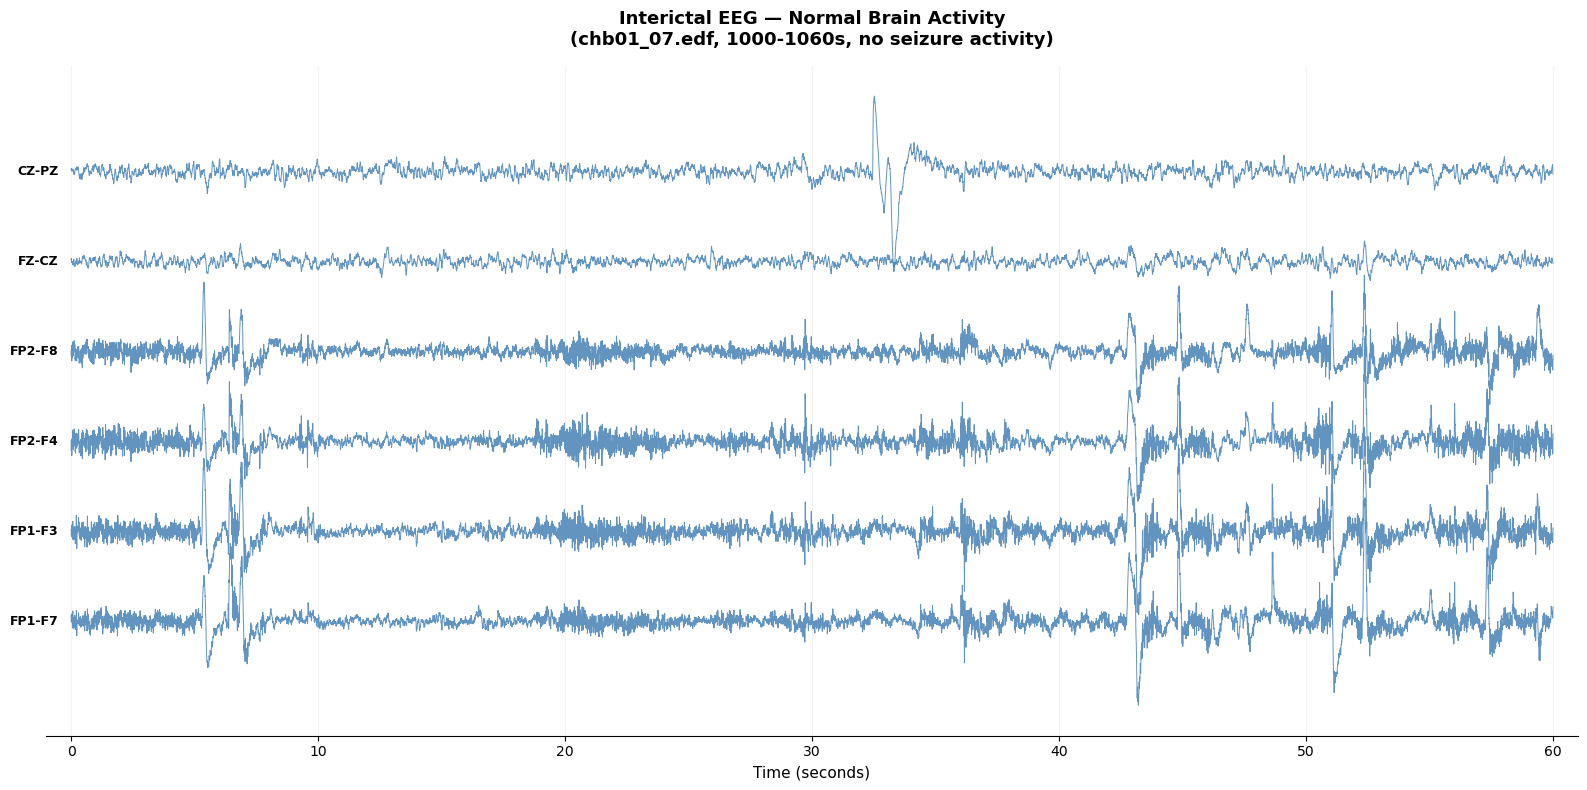

Loading preictal segment...


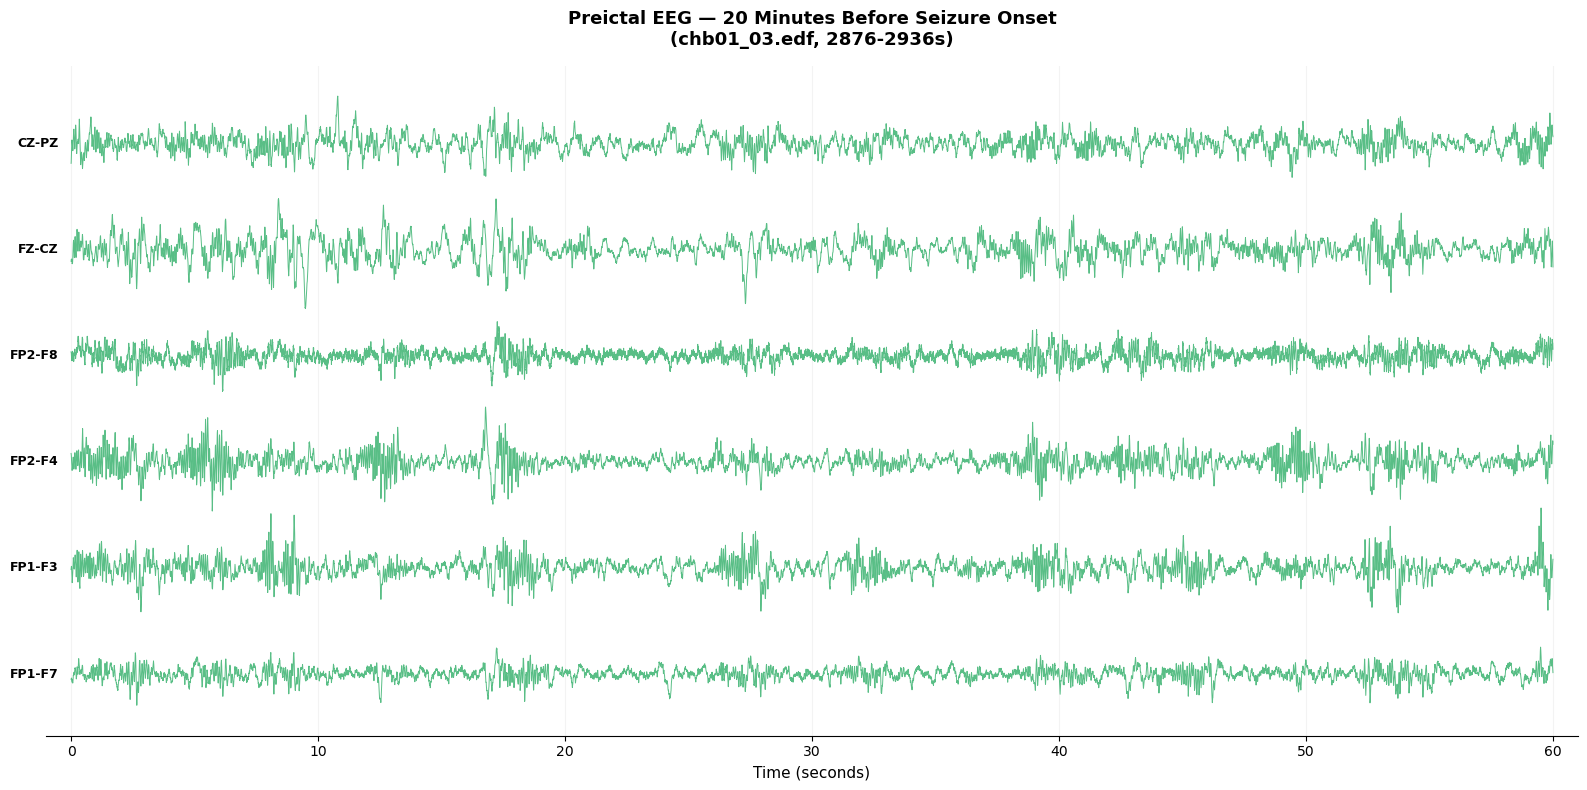

Loading ictal segment...


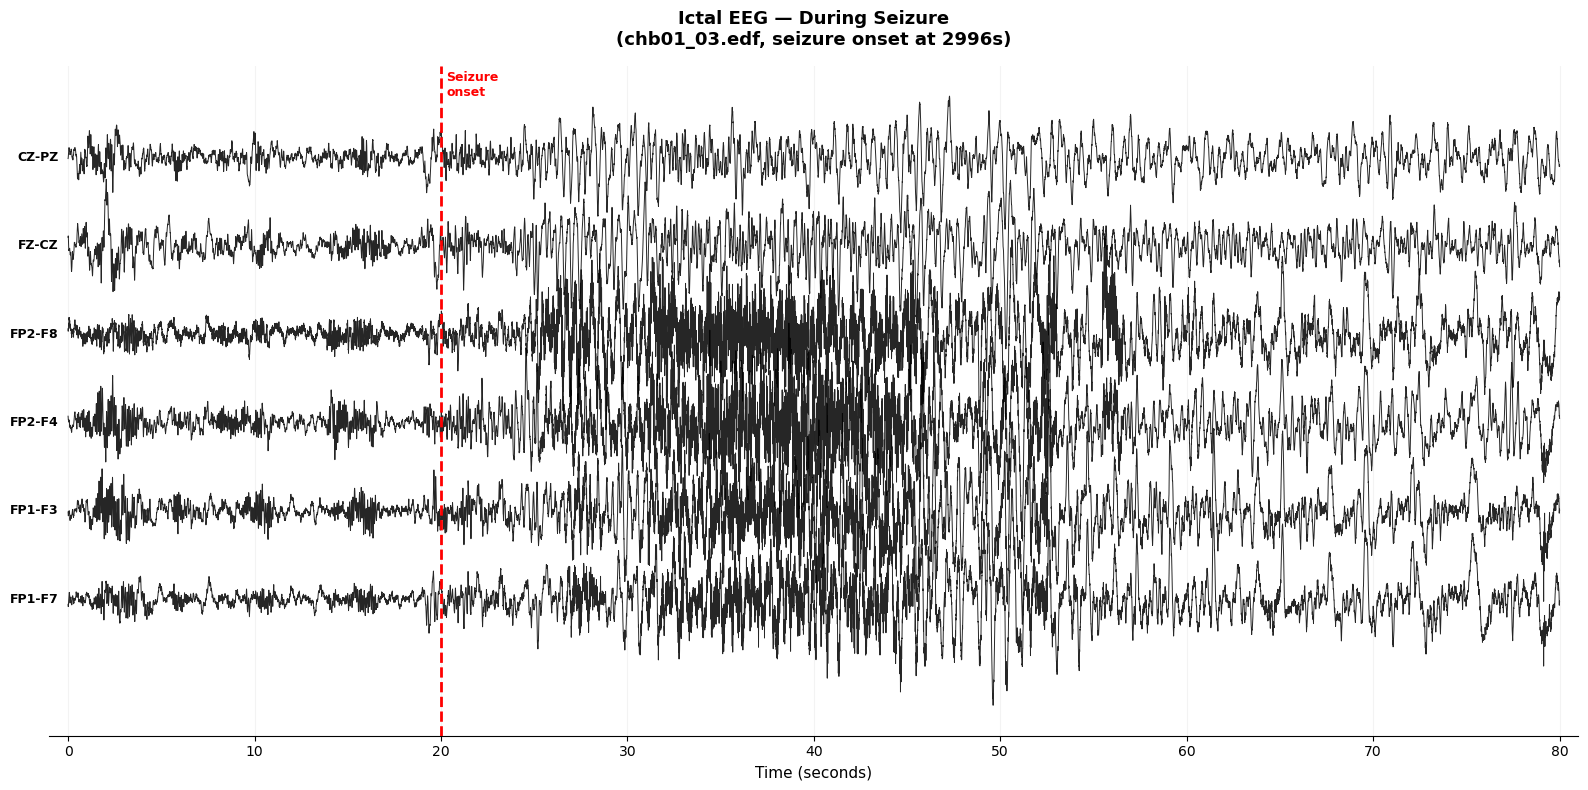

Loading postictal segment...


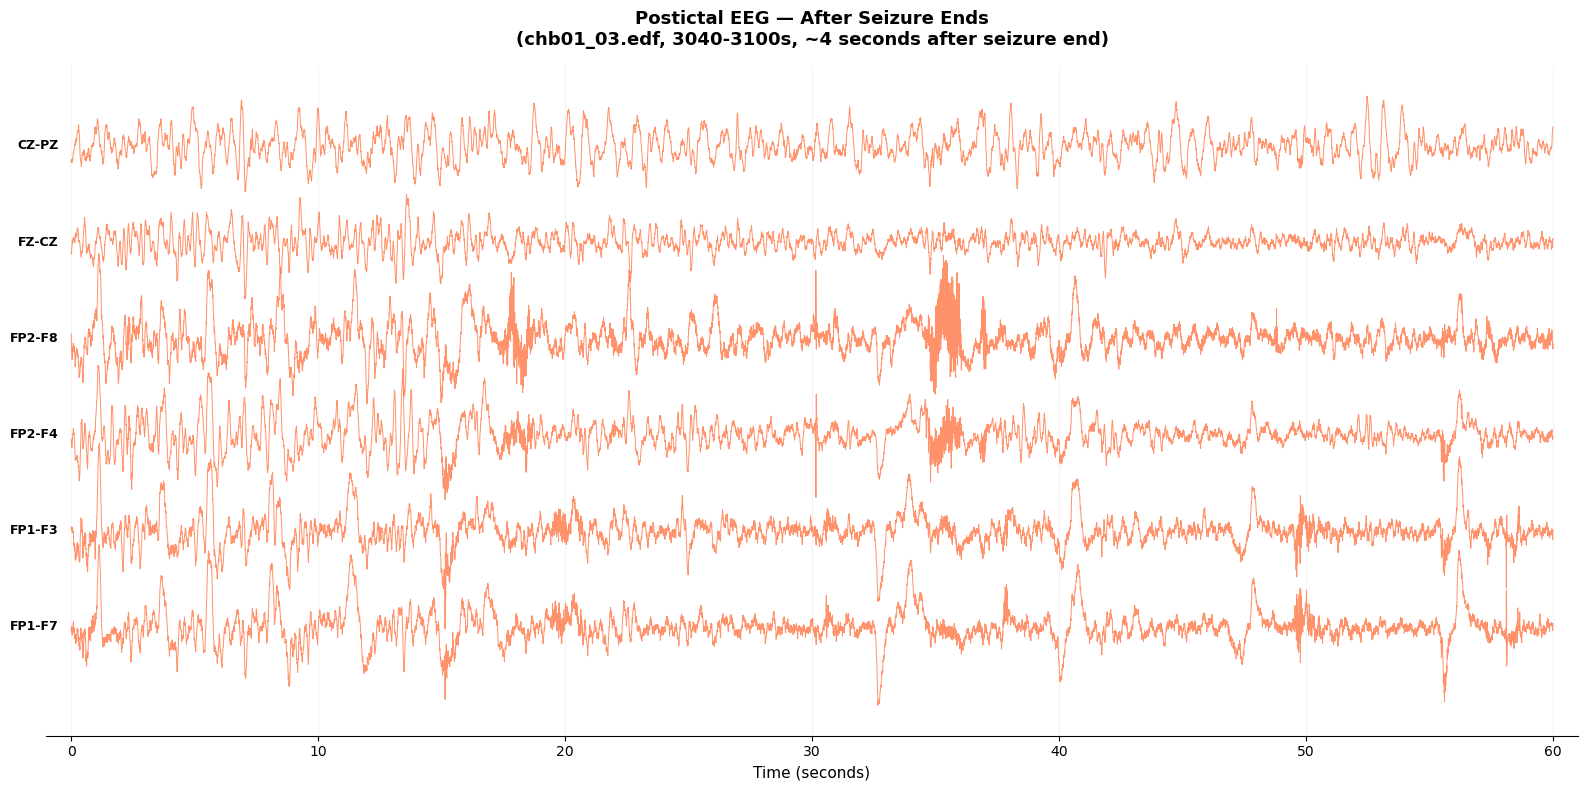


✓ All 4 EEG segments saved
  eeg_interictal.png
  eeg_preictal.png
  eeg_ictal.png
  eeg_postictal.png


In [1]:
# 07_raw_eeg_viewer.ipynb
# Raw EEG visualization — interictal, preictal, ictal, postictal
# for chb01 seizure 1

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pyedflib
import os

data_dir = '../data/chb01/'
sfreq    = 256

# use only 6 most informative channels instead of all 23
# covers left, right, frontal, temporal, central regions
channel_indices = [0,  4,  8,  12, 16, 17]
channel_names   = ['FP1-F7', 'FP1-F3', 'FP2-F4', 
                   'FP2-F8', 'FZ-CZ',  'CZ-PZ']

def load_segment(filename, start_sec, end_sec):
    """load a segment of EEG from a file"""
    filepath = os.path.join(data_dir, filename)
    f = pyedflib.EdfReader(filepath)
    signals = []
    for ch in channel_indices:
        sig = f.readSignal(ch)
        seg = sig[int(start_sec * sfreq):int(end_sec * sfreq)]
        signals.append(seg)
    f.close()
    return signals

def plot_eeg_segment(signals, start_sec, end_sec, title, 
                     seizure_onset=None, color='black'):
    """
    Plot EEG signals for multiple channels in a clean stacked layout.
    Each channel is offset vertically so they dont overlap.
    """
    duration = end_sec - start_sec
    time     = np.linspace(0, duration, signals[0].shape[0])
    
    fig, ax = plt.subplots(figsize=(16, 8))
    
    # plot each channel with vertical offset
    offset_scale = 400  # µV between channels
    
    for i, (sig, ch_name) in enumerate(zip(signals, channel_names)):
        offset = i * offset_scale
        
        # normalize signal for display
        sig_display = sig - np.mean(sig)  # remove DC offset
        
        ax.plot(time, sig_display + offset,
                linewidth=0.7, color=color, alpha=0.85)
        
        # channel label on left
        ax.text(-0.5, offset, ch_name,
                fontsize=9, ha='right', va='center',
                fontweight='bold')
    
    # mark seizure onset if provided
    if seizure_onset is not None:
        onset_time = seizure_onset - start_sec
        ax.axvline(onset_time, color='red', linewidth=2,
                   linestyle='--', label='Seizure onset', zorder=5)
        ax.text(onset_time + 0.3, 
                len(channel_names) * offset_scale * 0.95,
                'Seizure\nonset', color='red', fontsize=9,
                fontweight='bold')
    
    # formatting
    ax.set_xlim(-1, duration + 1)
    ax.set_xlabel('Time (seconds)', fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=15)
    ax.set_yticks([])  # hide y axis — channels are labeled directly
    ax.grid(True, alpha=0.15, axis='x')
    ax.spines['left'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    plt.tight_layout()
    return fig

# ── PLOT 1: INTERICTAL ────────────────────────────────────────
print("Loading interictal segment...")
signals_inter = load_segment('chb01_07.edf', 1000, 1060)
fig1 = plot_eeg_segment(
    signals_inter, 1000, 1060,
    title='Interictal EEG — Normal Brain Activity\n'
          '(chb01_07.edf, 1000-1060s, no seizure activity)',
    color='steelblue'
)
plt.savefig('eeg_interictal.png', dpi=300, bbox_inches='tight')
plt.show()

# ── PLOT 2: PREICTAL ─────────────────────────────────────────
print("Loading preictal segment...")
signals_pre = load_segment('chb01_03.edf', 2876, 2936)
fig2 = plot_eeg_segment(
    signals_pre, 2876, 2936,
    title='Preictal EEG — 20 Minutes Before Seizure Onset\n'
          '(chb01_03.edf, 2876-2936s)',
    color='mediumseagreen'
)
plt.savefig('eeg_preictal.png', dpi=300, bbox_inches='tight')
plt.show()

# ── PLOT 3: ICTAL ─────────────────────────────────────────────
print("Loading ictal segment...")
signals_ictal = load_segment('chb01_03.edf', 2976, 3056)
fig3 = plot_eeg_segment(
    signals_ictal, 2976, 3056,
    title='Ictal EEG — During Seizure\n'
          '(chb01_03.edf, seizure onset at 2996s)',
    seizure_onset=2996,
    color='black'
)
plt.savefig('eeg_ictal.png', dpi=300, bbox_inches='tight')
plt.show()

# ── PLOT 4: POSTICTAL ─────────────────────────────────────────
print("Loading postictal segment...")
signals_post = load_segment('chb01_03.edf', 3040, 3100)
fig4 = plot_eeg_segment(
    signals_post, 3040, 3100,
    title='Postictal EEG — After Seizure Ends\n'
          '(chb01_03.edf, 3040-3100s, ~4 seconds after seizure end)',
    color='coral'
)
plt.savefig('eeg_postictal.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ All 4 EEG segments saved")
print("  eeg_interictal.png")
print("  eeg_preictal.png")
print("  eeg_ictal.png")
print("  eeg_postictal.png")

Using matplotlib as 2D backend.


/var/folders/rk/w0plzk6n4033x_g087swl6t40000gn/T/ipykernel_49719/4157390777.py:4: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf('../data/chb01/chb01_03.edf',


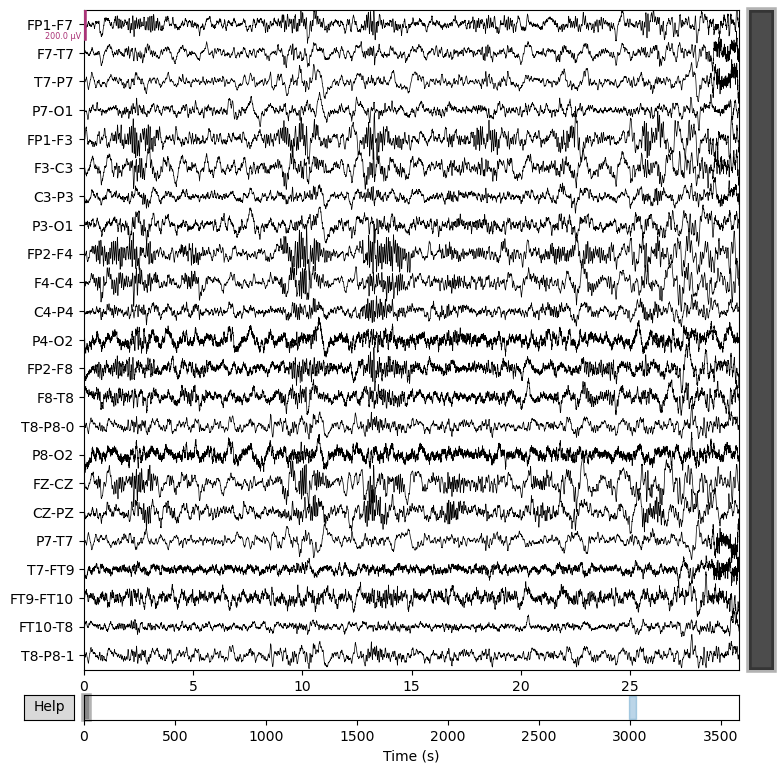

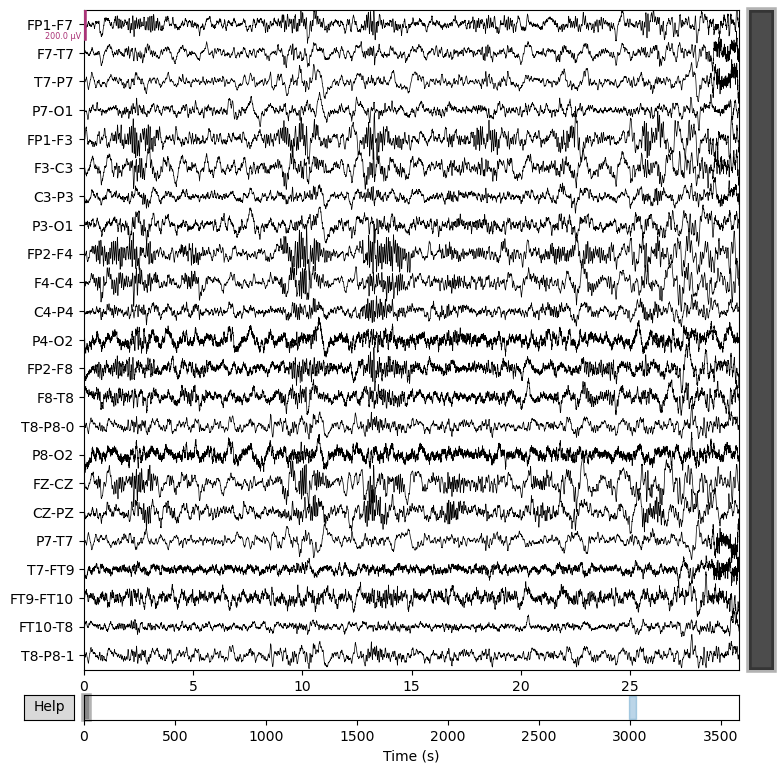

In [2]:
import mne

# load the file
raw = mne.io.read_raw_edf('../data/chb01/chb01_03.edf', 
                           preload=True, verbose=False)

# add seizure annotation so it shows up as a marker
raw.set_annotations(mne.Annotations(
    onset=[2996],           # seizure onset in seconds
    duration=[40],          # seizure duration
    description=['Seizure']
))

# open scrollable viewer
# use PageUp/PageDown to scroll through time
# use + / - to zoom in and out
raw.plot(
    duration=30,        # show 30 seconds at a time
    n_channels=23,      # show all channels
    scalings=dict(eeg=100e-6),  # scale in µV
    title='chb01_03.edf — scroll to view EEG (red = seizure onset)',
    show_scrollbars=True,
    block=True          # keeps window open
)